# BNPL Credit Risk — Exploratory Data Analysis (EDA)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/msmkarthik/BNPL-credit/blob/main/BNPL_CreditRisk_EDA.ipynb)

**Goal of the project:** build a credit score that predicts whether a Buy Now Pay Later (BNPL) customer will **default**.

**Goal of this notebook:** understand the data *before* building any model. EDA answers four questions:

1. **What is in the data?** Columns, types, ranges.
2. **Is the data clean?** Missing values, duplicates, odd or capped values.
3. **What does the target look like?** How many customers defaulted?
4. **Which columns are related to default, and which are not?** This decides which features go into the model.

> **How to read this notebook:**
> - **Section 0** explains all the basic concepts and Python syntax used. Start there if you are new to data science.
> - Before every code cell, a text cell explains **what we are doing and why** (the concept) and **how the code works** (line by line).
> - After every code cell, a **"What we see"** note explains the result in plain English.
> - **Section 11** collects all findings in one place.

**Dataset:** `Buy_Now_Pay_Later_BNPL_CreditRisk_Dataset.csv`, 10,345 customers × 17 columns.

**Running in Google Colab:** put the CSV in a folder called `bnpl` in your Google Drive (so the path is `My Drive/bnpl/Buy_Now_Pay_Later_BNPL_CreditRisk_Dataset.csv`), then run the cells in order. Section 1.1 connects the notebook to your Drive.

## 0. Before we start: the basics

This section is a short course on the ideas used in the rest of the notebook. Read it once; come back to it whenever a term is unfamiliar.

### 0.1 What is EDA, and why do it first?

**Exploratory Data Analysis (EDA)** is the step where we *get to know the data* before building any model. Think of it like **due diligence before an investment**: before you put money into a company, you read the financial statements, check for red flags, and understand what drives revenue. EDA does the same for a dataset.

Skipping EDA is the most common beginner mistake. A model will happily learn from broken, capped, or leaked data and give impressive-looking numbers that fall apart in real use. EDA protects against that.

A standard EDA follows these steps, and this notebook follows them in order:

| Step | Question it answers | Section |
|---|---|---|
| 1. Load and inspect | What columns do we have? What type is each one? | 2 |
| 2. Data quality | Are there missing values, duplicates, impossible or capped values? | 3 |
| 3. Target analysis | What are we predicting, and how common is it? | 4 |
| 4. Univariate analysis | What does each column look like *on its own*? | 5 |
| 5. Bivariate analysis | How does each column relate to the *target*? | 6 |
| 6. Derived-column checks | Are some columns just formulas of others? | 7 |
| 7. Correlation analysis | Which columns move together? | 8 |
| 8. Interaction analysis | Do two columns combined tell us more than each alone? | 9 |
| 9. Feature ranking | Which columns are most useful for predicting the target? | 10 |
| 10. Summary | What did we learn, and what do we do next? | 11 |

### 0.2 Key vocabulary

**Dataset, rows, columns.** Our data is a table, just like an Excel sheet. Each **row** is one customer. Each **column** is one piece of information about that customer (age, income, etc.).

**Target (or label).** The column we want to *predict*. Here it is `default_flag`: 1 if the customer defaulted, 0 if they repaid. In finance terms, this is the "bad" flag in a credit portfolio.

**Features (or predictors, variables).** All the other columns we can use to make the prediction: age, income, credit score, and so on.

**Numeric vs. categorical columns.**
- **Numeric** columns hold numbers where maths makes sense: income, age, credit score. You can average them.
- **Categorical** columns hold labels: employment type, country, product category. You *count* them, you don't average them. ("The average country" means nothing.)

**Distribution.** How the values of a column are spread out. Are most customers young or old? Are incomes clustered or spread? We look at distributions with **histograms**: bar charts where each bar counts how many customers fall in a range of values.

**Mean vs. median.**
- **Mean** = the average (add everything, divide by the count).
- **Median** = the middle value when everything is sorted. Half the customers are below it, half above.
- When a few customers have very large values (like a handful of very high earners), the mean gets pulled up but the median doesn't. So the median is often a better "typical customer" number.

**Skew.** A distribution is **right-skewed** when most values are small and a few are very large, giving a long tail to the right. Incomes are almost always right-skewed in real life.

**Percentiles / quartiles.** The 25th percentile (also called Q1) is the value below which 25% of customers fall. The 50th percentile is the median. The 75th percentile is Q3. These describe the spread without being distorted by extreme values.

**Outlier.** A value that is far away from the rest. It might be a genuine extreme (a billionaire customer) or a data error. EDA decides which.

**Default rate.** The share of customers who defaulted: number of defaulters ÷ number of customers. If 39 out of 100 customers defaulted, the default rate is 39%. This is the single most important number in this notebook. We compute it overall, and then for each group of customers.

### 0.3 More vocabulary (used later in the notebook)

**Binning (or banding).** Turning a numeric column into groups. For example, credit scores 300–850 become bands: "300", "301–400", "401–500", and so on. Credit policies do this all the time ("customers with scores below 600 need manual review"). Binning lets us compare default rates across groups with a simple bar chart.

**Quantiles / quintiles / deciles.** A special way of binning where every group has the *same number of customers*. Quintiles = 5 equal groups (each 20% of customers), deciles = 10 equal groups. Useful when values are skewed, because fixed-width bands would put most customers in one band.

**Correlation.** A number between −1 and +1 that measures how strongly two numeric columns move together in a straight line.
- **+1:** when one goes up, the other always goes up (perfect positive relationship).
- **−1:** when one goes up, the other always goes down (perfect negative relationship).
- **0:** no straight-line relationship.
- Rough guide: below 0.1 = negligible, 0.1–0.3 = weak, 0.3–0.6 = moderate, above 0.6 = strong.
- **Correlation is not causation.** Ice-cream sales and drowning are correlated (both rise in summer); ice cream doesn't cause drowning.

**Multicollinearity.** When two *features* are strongly correlated with *each other* (e.g. income and credit score). They then carry almost the same information. Some models, especially logistic regression, get confused about how much credit to give each one, and their coefficients become unstable.

**Data leakage.** Using information that would *not be available* at the moment the prediction is made. Example: if we're deciding at checkout whether to approve a BNPL loan, we cannot use "number of missed payments on this loan", because those payments haven't happened yet. A leaky model looks brilliant in testing and fails in real life. Spotting leakage is one of the most valuable things EDA does.

**Weight of Evidence (WoE) and Information Value (IV).** The credit-risk industry's standard tools for measuring how well a feature separates good customers from bad ones. Explained in detail in Section 10.

### 0.4 Python and Jupyter basics

**Running cells.** A notebook is made of **cells**. Text cells (like this one) explain things. Code cells contain Python. Click a code cell and press **Shift + Enter** to run it (in Colab you can also click the ▶ button on the left of the cell). The output appears below the cell.

**Order matters.** Cells must be run **top to bottom**, because later cells use variables created by earlier ones. If you see an error like `NameError: name 'df' is not defined`, it means an earlier cell hasn't been run. To run everything fresh: in Colab use **Runtime → Restart session and run all**; in Jupyter use **Kernel → Restart & Run All**.

**Colab sessions reset.** Colab disconnects after a period of inactivity and forgets all variables. When you come back, run all the cells again from the top (including the Google Drive connection).

**The pandas basics you'll see repeatedly:**

| Code | What it means |
|---|---|
| `df` | Our whole table (a pandas **DataFrame**). The name is short for "data frame". |
| `df["age"]` | One column of the table (a pandas **Series**). |
| `df[["age", "credit_score"]]` | Several columns (note the double brackets: a list of names inside). |
| `df.head()` | Show the first 5 rows. |
| `df.shape` | Number of rows and columns, as `(rows, columns)`. |
| `df["age"].mean()` | Average of a column. Also `.median()`, `.min()`, `.max()`, `.sum()`. |
| `df["employment_type"].value_counts()` | Count how many rows have each value. |
| `df.groupby("employment_type")["default_flag"].mean()` | **Split** customers into groups by employment type, then take the **average default flag** of each group. Because the flag is 0 or 1, its average *is* the default rate. This is the single most-used line in credit EDA. |
| `df["age"] > 30` | A True/False answer for every row. Used to filter: `df[df["age"] > 30]` keeps only customers over 30. |
| `pd.cut(...)` | Put numbers into bands we define (e.g. credit score bands). |
| `pd.qcut(...)` | Put numbers into equal-sized groups (quintiles, deciles). |

**Why the average of a 0/1 column is a rate.** Suppose 5 customers have `default_flag` values 1, 0, 0, 1, 0. The average is (1+0+0+1+0) ÷ 5 = 0.4 = 40%. That is exactly the share who defaulted. We use this trick throughout.

**`#` in code** starts a comment: a note for humans that Python ignores.

## 1. Setup

### 1.1 Connect to the data (Google Colab or your own computer)

This notebook can run in two places:

- **Google Colab** (recommended for beginners): a free notebook environment in the browser. Nothing to install. The data is read from your **Google Drive**, from a folder called `bnpl`.
- **Your own computer** (Jupyter): the data is read from the same folder as the notebook.

**One-time preparation for Colab:**
1. Open [Google Drive](https://drive.google.com).
2. In **My Drive**, create a folder called exactly `bnpl` (lowercase).
3. Upload `Buy_Now_Pay_Later_BNPL_CreditRisk_Dataset.csv` into it. Keep the file name exactly as it is.

#### What we're doing
Telling the notebook **where the data file is**.

Google Colab runs on a computer in Google's cloud, not on your laptop. That computer can't see your files until you connect it to your **Google Drive**. This step is called **mounting** the Drive: afterwards, your Drive appears as a folder inside Colab, at `/content/drive/MyDrive/`.

**When you run this cell in Colab:**
1. A pop-up asks for permission to access your Google Drive.
2. Choose your Google account and click **Allow** (or **Continue**).
3. After a few seconds you should see `Mounted at /content/drive` and `Found the dataset: ...`.

You need to do this every time you open the notebook or Colab restarts.

#### How the code works
- `import os` loads Python's built-in tools for working with files and folders.
- `try: ... except ImportError: ...` means "try the first block; if it fails because a library is missing, run the second block instead". The `google.colab` library exists **only inside Colab**, so:
  - **In Colab**, the import works, we mount the Drive, and set `DATA_DIR` to the `bnpl` folder in your Drive.
  - **On your own computer**, the import fails, and we set `DATA_DIR = "."`, which means "the folder this notebook is in".
  - This way, the same notebook works in both places without any changes.
- `os.path.join(DATA_DIR, "....csv")` glues the folder and the file name into one full path, adding the `/` in between.
- `os.path.exists(DATA_PATH)` checks whether the file is really there.
  - If it's missing, we print what *is* in the folder, which makes typos easy to spot. Common causes: the folder is not called exactly `bnpl`, it isn't directly inside **My Drive**, or the file name was changed (e.g. `... (1).csv` after a second download).

`DATA_PATH` is used in Section 2 to load the data.

In [ ]:
import os

try:
    # This import only works inside Google Colab
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/bnpl"
    print("Running in Google Colab. Google Drive is connected.")
except ImportError:
    DATA_DIR = "."   # "." means "the folder this notebook is in"
    print("Running locally. Reading the data from the notebook's folder.")

DATA_PATH = os.path.join(DATA_DIR, "Buy_Now_Pay_Later_BNPL_CreditRisk_Dataset.csv")

if os.path.exists(DATA_PATH):
    print("Found the dataset:", DATA_PATH)
else:
    print("Dataset NOT found at:", DATA_PATH)
    if os.path.isdir(DATA_DIR):
        print("Files that ARE in", DATA_DIR, ":", os.listdir(DATA_DIR))
    else:
        print("The folder", DATA_DIR, "does not exist. Check the folder name in Google Drive.")

### 1.2 Load the libraries

We use three standard libraries:

| Library | What it does |
|---|---|
| `pandas` | Tables (like Excel sheets in Python) |
| `numpy` | Maths on columns of numbers |
| `matplotlib` | Charts |

All three come pre-installed in Google Colab. The second cell below sets a consistent chart style and defines two small helper functions so we don't repeat the same plotting code many times.

#### What we're doing
Loading the **libraries** (ready-made toolkits) we need. Python on its own can't read CSV files or draw charts easily; libraries add those abilities.

#### How the code works
- `import numpy as np`: loads NumPy and gives it the short nickname `np`. Everyone uses these nicknames, so you'll see `np.` and `pd.` in almost every data science notebook online.
- `import pandas as pd`: loads pandas, the table library, as `pd`.
- `import matplotlib.pyplot as plt`: loads the charting library as `plt`.
- `import matplotlib.ticker as mtick`: a small helper to format chart axes as percentages.
- The three `pd.set_option(...)` lines are cosmetic: show all columns instead of hiding some with `...`, use a wider display, and print decimals with 2 places and thousand separators (e.g. `35,053.38`).

**If this cell fails** with `ModuleNotFoundError`, the library isn't installed. This won't happen in Colab. On your own computer, run `pip install pandas matplotlib` in a terminal and try again.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

#### What we're doing
Two things:
1. Setting a **consistent look** for every chart (colours, gridlines, font sizes), so we don't repeat styling code in every cell.
2. Defining two **helper functions**. A *function* is a reusable recipe: you write the steps once, give it a name, and then "call" it with different inputs. We will make the same kind of chart (default rate by group) about 15 times, so a function saves a lot of repetition.

#### How the code works
- The capitalised names (`BLUE`, `ORANGE`, ...) are colour codes. Blue is used for normal bars; orange highlights the overall default rate line, so it stands out.
- `plt.rcParams.update({...})` changes matplotlib's default settings: remove the top/right border lines, add light horizontal gridlines, left-align titles, and so on.
- **`plot_default_rate(data, col, title, ...)`** does the following:
  1. `data.groupby(col)["default_flag"].agg(rate="mean", n="size")` splits customers into groups by the column `col`, then for each group computes the **default rate** (`mean` of the 0/1 flag) and the **number of customers** (`size`).
  2. Draws one bar per group, with height = default rate.
  3. Draws a dashed orange line at the **overall** default rate, so you can instantly see which groups are riskier (bar above the line) or safer (bar below the line) than average.
  4. Writes the percentage on top of each bar, and the customer count `n=` inside the bar. The count matters: a 90% default rate based on 5 customers means very little; based on 5,000 customers it's a strong signal.
- **`default_table(data, col)`** returns the same numbers as a table (customers, defaults, default rate) for when you want exact figures.

You don't need to understand every styling line. The important part is the logic of `plot_default_rate`: **group → average the default flag → compare to overall**.

Note that `overall_rate` is used inside the function but only created in Section 4. That's fine, because the function isn't *run* until later.

In [3]:
# ---- Chart style -----------------------------------------------------------
BLUE   = "#2a78d6"   # main colour / "Repaid"
ORANGE = "#eb6834"   # "Defaulted"
INK    = "#0b0b0b"
INK_2  = "#52514e"
MUTED  = "#898781"
GRID   = "#e1e0d9"
AXIS   = "#c3c2b7"

plt.rcParams.update({
    "figure.figsize": (8, 4),
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK_2,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlecolor": INK,
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelcolor": INK_2,
    "ytick.labelcolor": INK_2,
    "legend.frameon": False,
    "font.size": 10,
})


def plot_default_rate(data, col, title, order=None, xlabel=None, ax=None):
    # Bar chart of the default rate for each group of `col`,
    # with a dashed line for the overall default rate.
    g = data.groupby(col, observed=True)["default_flag"].agg(rate="mean", n="size")
    if order is not None:
        g = g.reindex(order)
    ax = ax or plt.subplots()[1]
    labels = [str(i) for i in g.index]
    bars = ax.bar(labels, g["rate"], color=BLUE, width=0.6)
    ax.axhline(overall_rate, color=ORANGE, linestyle="--", linewidth=1.5,
               label=f"Overall default rate ({overall_rate:.0%})")
    ax.legend(loc="upper right", fontsize=8)
    for b, (rate, n) in zip(bars, g.itertuples(index=False)):
        ax.text(b.get_x() + b.get_width() / 2, rate + 0.01, f"{rate:.0%}",
                ha="center", va="bottom", fontsize=9, color=INK)
        ax.text(b.get_x() + b.get_width() / 2, 0.01, f"n={n:,}",
                ha="center", va="bottom", fontsize=8, color="white")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_ylim(0, max(g["rate"].max() * 1.35, overall_rate * 1.6))
    ax.set_ylabel("Default rate")
    ax.set_xlabel(xlabel or col)
    ax.set_title(title)
    return g


def default_table(data, col, order=None):
    # Same numbers as the chart, as a table.
    t = data.groupby(col, observed=True)["default_flag"].agg(customers="size", defaults="sum", default_rate="mean")
    if order is not None:
        t = t.reindex(order)
    t["default_rate"] = (t["default_rate"] * 100).round(1).astype(str) + "%"
    return t

## 2. Load the data and take a first look

#### What we're doing
**Loading the data** from the CSV file into a pandas table called `df`, then looking at the first few rows.

A **CSV** (comma-separated values) file is a plain-text table: each line is a row, and commas separate the columns. Excel can open it too.

Always look at the raw rows first. It's like opening a bank statement before analysing it: you check that the columns are what you expect, the numbers look sensible, and nothing is obviously garbled.

#### How the code works
- `pd.read_csv(DATA_PATH)` reads the file and returns a DataFrame. We store it in the variable `df`. `DATA_PATH` was set in Section 1.1: your Google Drive's `bnpl` folder in Colab, or the notebook's folder locally. If you get `FileNotFoundError`, go back to Section 1.1 and check its message.
- `df.shape` gives `(rows, columns)`. `df.shape[0]` is the row count, `df.shape[1]` the column count.
- `f"Rows: {df.shape[0]:,}"` is an **f-string**: text with values inserted in `{}`. The `:,` adds thousand separators (10,345 instead of 10345).
- `df.head()` shows the first 5 rows. `df.head(10)` would show 10. `df.tail()` shows the last 5.

In [4]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
df.head()

Rows: 10,345   Columns: 17


,user_id,age,employment_type,monthly_income,credit_score,purchase_amount,product_category,bnpl_installments,repayment_delay_days,missed_payments,default_flag,app_usage_frequency,location,transaction_date,debt_to_income_ratio,risk_score,customer_segment
0,1,56,Salaried,"68,529.50",552,"5,000.00",Electronics,12,13,1,0,8.49,Australia,2023-06-10,0.07,165.20,Medium Risk
1,2,19,Student,"7,247.85",300,"1,073.23",Fashion,12,13,1,0,3.09,USA,2024-10-07,0.15,266.00,High Risk
2,3,20,Self-Employed,"41,582.26",471,"5,000.00",Electronics,3,19,2,0,3.33,Australia,2023-04-05,0.12,229.60,High Risk
3,4,21,Salaried,"14,423.46",300,"4,076.83",Sports,6,18,5,1,5.86,Germany,2023-06-24,0.28,356.00,High Risk
4,5,43,Salaried,"42,845.50",512,"5,000.00",Electronics,9,0,0,0,7.36,India,2024-10-19,0.12,135.20,High Risk


#### What we're doing
Checking the **data type** of each column and how many values are filled in.

Data types matter because they decide what you can do with a column:

| pandas type | Meaning | Examples here |
|---|---|---|
| `int64` | Whole numbers | age, credit_score, missed_payments |
| `float64` | Decimal numbers | monthly_income, debt_to_income_ratio |
| `object` | Text (strings) | employment_type, location, **transaction_date** |

Note that `transaction_date` is read as **text**, not as a date. pandas doesn't automatically recognise dates in CSVs. We convert it in Section 3 so we can work with months and quarters.

#### How the code works
`df.info()` prints one line per column: its position, name, **non-null count** (how many rows have a value; if this is less than 10,345, there are missing values), and type. At the bottom it shows memory usage.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10345 entries, 0 to 10344
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   user_id               10345 non-null  int64  
 1   age                   10345 non-null  int64  
 2   employment_type       10345 non-null  object 
 3   monthly_income        10345 non-null  float64
 4   credit_score          10345 non-null  int64  
 5   purchase_amount       10345 non-null  float64
 6   product_category      10345 non-null  object 
 7   bnpl_installments     10345 non-null  int64  
 8   repayment_delay_days  10345 non-null  int64  
 9   missed_payments       10345 non-null  int64  
 10  default_flag          10345 non-null  int64  
 11  app_usage_frequency   10345 non-null  float64
 12  location              10345 non-null  object 
 13  transaction_date      10345 non-null  object 
 14  debt_to_income_ratio  10345 non-null  float64
 15  risk_score         

### Data dictionary

There is no official documentation, so this is our reading of each column.

| Column | Type | Meaning (our interpretation) |
|---|---|---|
| `user_id` | ID | Unique customer ID — not a feature |
| `age` | Number | Customer age (18–59) |
| `employment_type` | Category | Salaried / Self-Employed / Student / Unemployed |
| `monthly_income` | Number | Monthly income |
| `credit_score` | Number | Bureau credit score (300–850) |
| `purchase_amount` | Number | Value of the BNPL purchase |
| `product_category` | Category | What was bought |
| `bnpl_installments` | Number | Number of instalments: 3, 6, 9 or 12 |
| `repayment_delay_days` | Number | Days late on past repayments |
| `missed_payments` | Number | Number of missed past payments |
| **`default_flag`** | **0 / 1** | **Target: 1 = customer defaulted** |
| `app_usage_frequency` | Number | How often the customer uses the app (1–10) |
| `location` | Category | Country |
| `transaction_date` | Date | Date of purchase |
| `debt_to_income_ratio` | Number | Purchase amount ÷ monthly income |
| `risk_score` | Number | A pre-calculated risk score (checked in Section 7) |
| `customer_segment` | Category | High / Medium / Low Risk label (checked in Section 7) |

## 3. Data quality checks

Before trusting any number, we check for the usual problems: missing values, duplicates, impossible values, and values that look artificially capped.

#### What we're doing
The first **data quality checks**:

1. **Missing values.** Empty cells. In real data, these are very common (a customer didn't fill in their income, a system failed to record a value). Most models can't handle missing values, so we must find them and decide whether to fill them in or drop those rows.
2. **Unique values per column.** Tells us what kind of column it is. A column with 4 unique values (employment type) is categorical; one with 9,984 unique values (income) is continuous numeric; one where *every* value is unique (user_id) is an identifier.
3. **Duplicate rows.** The exact same row appearing twice, often from a data-export error. Duplicates make some customers count double and distort every rate.
4. **Duplicate IDs.** If the same `user_id` appeared several times, each row would be a separate *transaction* and we'd have a customer **history**. If each ID appears once, each row is one customer with one purchase.

#### How the code works
- `df.isna()` gives True for every empty cell; `.sum()` counts the Trues per column (True counts as 1).
- `df.nunique()` counts distinct values per column.
- `pd.DataFrame({...})` puts both results side by side in one table.
- `df.duplicated()` marks each row that is an exact copy of an earlier row; `.sum()` counts them.
- `df["user_id"].duplicated().sum()` does the same check for the ID column only.

In [6]:
quality = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "unique_values": df.nunique(),
})
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate user_ids:", df["user_id"].duplicated().sum())
quality

Duplicate rows: 0
Duplicate user_ids: 0


,missing_values,unique_values
user_id,0,10345
age,0,42
employment_type,0,4
monthly_income,0,9984
credit_score,0,534
purchase_amount,0,4011
product_category,0,5
bnpl_installments,0,4
repayment_delay_days,0,33
missed_payments,0,8


**What we see:** no missing values, no duplicate rows, and every `user_id` appears exactly once. So **each row is one customer**, and there is **no transaction history** per customer.

#### What we're doing
**Summary statistics** for every numeric column, the "financial ratios" of a dataset. In one table we get, per column:

| Row in output | Meaning |
|---|---|
| `count` | Number of filled-in values |
| `mean` | Average |
| `std` | **Standard deviation**: how spread out the values are around the mean. Small = values cluster tightly; large = widely spread. Roughly, most values sit within 2 standard deviations of the mean. |
| `min` / `max` | Smallest / largest value |
| `25%` / `50%` / `75%` | Quartiles. `50%` is the median. |

#### What to look for
- **Impossible values:** negative ages or incomes, credit scores outside 300–850, ratios below 0.
- **Mean far from median:** a sign of skew. For `monthly_income`, the mean (35,053) is much higher than the median (23,800), so a minority of high earners pulls the average up.
- **Many values at min or max:** a sign of **capping**. Look at `purchase_amount`: the median, the 75th percentile and the maximum are *all* 5,000. That means more than half of the rows sit exactly at the maximum, which is suspicious.

#### How the code works
- `numeric_cols` is a Python **list** of column names (square brackets, comma-separated).
- `df[numeric_cols]` selects just those columns. `.describe()` computes the statistics. `.T` **transposes** the table (swaps rows and columns) so each column becomes a row, which is easier to read.

In [7]:
numeric_cols = ["age", "monthly_income", "credit_score", "purchase_amount", "bnpl_installments",
                "repayment_delay_days", "missed_payments", "app_usage_frequency",
                "debt_to_income_ratio", "risk_score"]
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,"10,345.00",38.56,12.13,18.00,28.00,39.00,49.00,59.00
monthly_income,"10,345.00","35,053.38","27,084.52","5,000.00","12,207.02","23,800.52","55,276.93","145,767.12"
credit_score,"10,345.00",448.18,136.52,300.00,332.00,403.00,547.00,850.00
purchase_amount,"10,345.00","3,979.40","1,500.83",100.00,"2,990.72","5,000.00","5,000.00","5,000.00"
bnpl_installments,"10,345.00",7.48,3.36,3.00,3.00,9.00,9.00,12.00
repayment_delay_days,"10,345.00",8.74,6.78,0.00,2.00,9.00,14.00,33.00
missed_payments,"10,345.00",1.02,1.00,0.00,0.00,1.00,2.00,7.00
app_usage_frequency,"10,345.00",5.52,2.59,1.00,3.30,5.55,7.75,10.00
debt_to_income_ratio,"10,345.00",0.18,0.12,0.00,0.08,0.14,0.27,0.72
risk_score,"10,345.00",198.53,67.54,0.00,153.60,202.80,250.80,398.00


**What we see:** all ranges are plausible (no negative incomes, no credit scores outside 300–850). But a few columns have a suspicious number of rows sitting exactly on the minimum or maximum. Let's count them.

#### What we're doing
Counting exactly how many customers sit **on the boundary values** we spotted above.

When a large share of rows has exactly the minimum or maximum value, it usually means one of:
- **A cap or limit.** E.g. a BNPL provider allows purchases up to 5,000, so every bigger request is recorded as 5,000.
- **A floor or default value.** E.g. customers with no credit history are given the lowest score, 300.
- **Clipping during data generation** (common in synthetic datasets).

The true values are hidden behind the cap, which can mislead the analysis, so we need to know how big the problem is.

#### How the code works
- `(df["purchase_amount"] == 5000)` gives True/False per row (note: `==` *compares*; a single `=` *assigns*). `.sum()` counts the Trues.
- We build a small table and add a percentage column: `rows / len(df) * 100`. `len(df)` is the total number of rows.

In [8]:
edge_checks = pd.DataFrame({
    "value": ["= 5,000 (max)", "= 300 (min)", "= 5,000 (min)"],
    "rows": [(df["purchase_amount"] == 5000).sum(),
             (df["credit_score"] == 300).sum(),
             (df["monthly_income"] == 5000).sum()],
}, index=["purchase_amount", "credit_score", "monthly_income"])
edge_checks["% of rows"] = (edge_checks["rows"] / len(df) * 100).round(1)
edge_checks

,value,rows,% of rows
purchase_amount,"= 5,000 (max)",6053,58.50
credit_score,= 300 (min),1373,13.30
monthly_income,"= 5,000 (min)",355,3.40


#### What we're doing
**Visualising** the two capped columns with **histograms**, so the problem is obvious at a glance.

**How to read a histogram:** the horizontal axis is the value (e.g. purchase amount), split into ranges called **bins**. The height of each bar is the number of customers whose value falls in that range. A tall isolated bar at one end of the chart means many customers share that exact value, which is the signature of a cap or floor.

#### How the code works
- `plt.subplots(1, 2, figsize=(11, 3.8))` creates a figure with **1 row and 2 columns** of charts, 11 by 3.8 inches. It returns the figure (`fig`) and a list of the two chart areas (`axes`). `axes[0]` is the left chart, `axes[1]` the right.
- `.hist(column, bins=40)` draws a histogram with 40 bins.
- `.set_title`, `.set_xlabel`, `.set_ylabel` add text.
- `plt.tight_layout()` stops labels overlapping; `plt.show()` displays the figure.

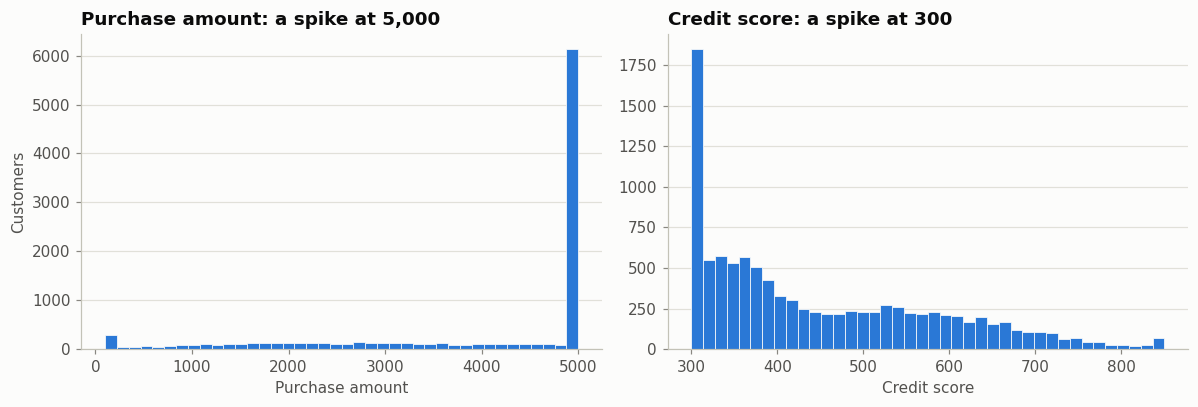

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df["purchase_amount"], bins=40, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
axes[0].set_title("Purchase amount: a spike at 5,000")
axes[0].set_xlabel("Purchase amount")
axes[0].set_ylabel("Customers")
axes[1].hist(df["credit_score"], bins=40, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
axes[1].set_title("Credit score: a spike at 300")
axes[1].set_xlabel("Credit score")
plt.tight_layout()
plt.show()

**What we see:**

- **59% of purchases are exactly 5,000.** This looks like a cap (a maximum BNPL limit, or a ceiling applied when the data was generated). We cannot know the "true" amount for these customers, so we should be careful interpreting `purchase_amount`.
- **13% of credit scores are exactly 300**, the lowest possible score. In real credit data this is often how *"no credit history"* customers are recorded.
- 3% of incomes sit at the 5,000 floor.

These are **not errors to delete**, but they are worth mentioning as limitations.

#### What we're doing
Converting the date column from text into a real **date type**, then checking **which time period** the data covers.

Time coverage matters in credit risk because default rates change with the economy. If a dataset only covers a recession, a model trained on it will overestimate risk in good times. If there are gaps, we should know about them.

#### How the code works
- `pd.to_datetime(...)` turns text like `"2023-06-10"` into a date pandas understands. We overwrite the old column with the converted one.
- `.min()` and `.max()` give the earliest and latest date. `.date()` drops the time part for cleaner printing.
- `.dt` unlocks date features: `.dt.year`, `.dt.month`, and here `.dt.to_period("Q")`, which converts each date to its **quarter** (e.g. 2023Q1 = Jan–Mar 2023).
- `.value_counts().sort_index()` counts transactions per quarter and sorts them in time order.

In [10]:
df["transaction_date"] = pd.to_datetime(df["transaction_date"])
print("From", df["transaction_date"].min().date(), "to", df["transaction_date"].max().date())
df["transaction_date"].dt.to_period("Q").value_counts().sort_index()

From 2023-01-01 to 2024-12-31


transaction_date
2023Q1    2617
2023Q2    2528
2024Q3    2618
2024Q4    2582
Freq: Q-DEC, Name: count, dtype: int64

**What we see:** the data covers only **Jan–Jun 2023** and **Jul–Dec 2024**. There is a one-year gap in the middle. We check later whether the default rate changes over time.

## 4. The target: how many customers defaulted?

#### What we're doing
**Target analysis**: looking at the column we want to predict. This is the most important single check in any classification EDA, because it tells us:

1. **The base rate.** What share of customers default? Every later group is compared against this number.
2. **Class balance.** Are both outcomes reasonably common? If only 1% of customers defaulted (an **imbalanced** dataset), a lazy model that predicts "nobody defaults" would be 99% accurate and completely useless. So the class balance tells us which evaluation metrics to use later.

**A quick note on evaluation metrics** (used in the modelling stage, not here):
- **Accuracy:** share of all predictions that are correct. Misleading when classes are imbalanced.
- **Precision:** of the customers the model *flags* as defaulters, how many actually default? (Low precision = rejecting many good customers = lost revenue.)
- **Recall:** of the customers who *actually* default, how many did the model catch? (Low recall = approving bad customers = credit losses.)
- **AUC:** how well the model ranks customers from riskiest to safest, from 0.5 (random guessing) to 1.0 (perfect).

#### How the code works
- `df["default_flag"].mean()` gives the overall default rate (the average of a 0/1 column, as explained in Section 0.4). We store it in `overall_rate` because the plotting helper uses it as the dashed reference line.
- `.map({0: "Repaid", 1: "Defaulted"})` replaces 0/1 with readable labels; `.value_counts()` counts each.
- `ax.barh(...)` draws a **horizontal** bar chart. The loop `for b, v in zip(bars, counts.values)` walks through each bar and its value together and writes the count and percentage beside it.

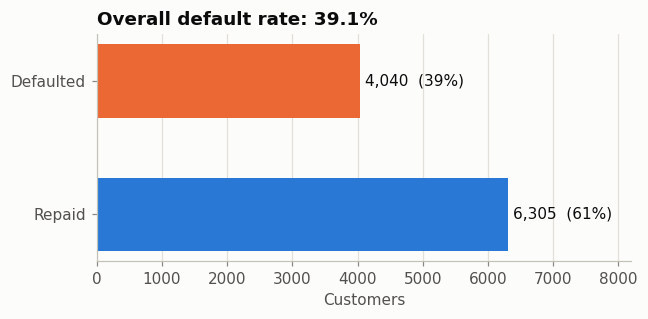

In [11]:
overall_rate = df["default_flag"].mean()
counts = df["default_flag"].map({0: "Repaid", 1: "Defaulted"}).value_counts()

fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.barh(counts.index, counts.values, color=[BLUE, ORANGE], height=0.55)
for b, v in zip(bars, counts.values):
    ax.text(v + 80, b.get_y() + b.get_height() / 2, f"{v:,}  ({v / len(df):.0%})", va="center", color=INK)
ax.set_xlim(0, counts.max() * 1.3)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_title(f"Overall default rate: {overall_rate:.1%}")
ax.set_xlabel("Customers")
plt.tight_layout()
plt.show()

**What we see:** **39% of customers defaulted.** That is very high compared to real lending portfolios (usually low single digits), which confirms the data is synthetic or deliberately risky.

For modelling, this is good news: the two classes are reasonably balanced (61 / 39). That means plain accuracy is not hugely misleading. We should still report **precision, recall and AUC**, because a missed defaulter (a loss) costs more than a rejected good customer (lost revenue).

## 5. Each column on its own (univariate analysis)

First we look at the *shape* of each column, without the target.

#### What we're doing
**Univariate analysis** ("uni" = one): looking at each numeric column **on its own**, ignoring the target for now.

Why? Before asking "does income predict default?", we need to know what income looks like: Is it skewed? Are there extreme values? Are there spikes at particular values? This affects how we band it, whether we need to transform it, and how much to trust it.

**Shapes to recognise:**
- **Uniform (flat):** every value roughly equally common. Unusual in real life, and a hint the data may be synthetic.
- **Right-skewed:** a tall peak on the left, long tail to the right. Typical for income and amounts.
- **Spike:** one value much taller than its neighbours, usually a cap, floor or default value.
- **Discrete:** only a few possible values (e.g. instalments are always 3, 6, 9 or 12). Shown as separate bars.

#### How the code works
- `plt.subplots(2, 4, ...)` creates a grid of 2 rows × 4 columns = 8 small charts.
- `axes.ravel()` flattens the grid into a simple list, so we can loop over it. `zip(axes.ravel(), cols)` pairs each chart area with one column name.
- Inside the loop: if a column has 12 or fewer distinct values (`nunique() <= 12`), we draw a **bar chart of counts** (one bar per value). Otherwise we draw a **histogram**.
- For whole-number columns with a small range (like age), we set one bin per value. Otherwise bars alternate tall/short because some bins happen to contain two integer values and others one.

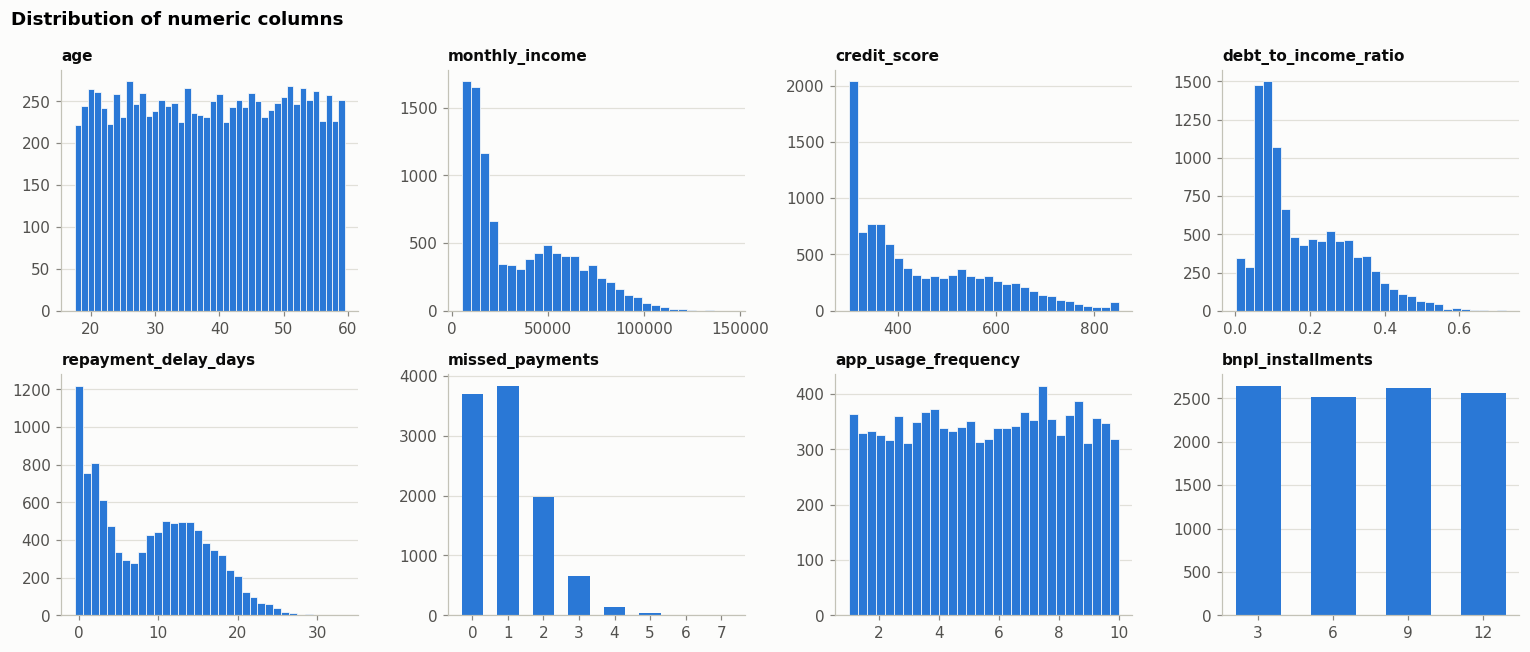

In [12]:
cols = ["age", "monthly_income", "credit_score", "debt_to_income_ratio",
        "repayment_delay_days", "missed_payments", "app_usage_frequency", "bnpl_installments"]
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axes.ravel(), cols):
    if df[c].nunique() <= 12:
        vc = df[c].value_counts().sort_index()
        ax.bar(vc.index.astype(str), vc.values, color=BLUE, width=0.6)
    else:
        # whole-number columns get one bar per value, so bars don't alternate tall/short
        small_int_range = df[c].dtype == "int64" and df[c].max() - df[c].min() <= 60
        bins = np.arange(df[c].min(), df[c].max() + 2) - 0.5 if small_int_range else 30
        ax.hist(df[c], bins=bins, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
    ax.set_title(c, fontsize=10)
fig.suptitle("Distribution of numeric columns", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**What we see:**

- **`monthly_income`** and **`credit_score`** are *right-skewed*: many low values and a long tail of high values.
- **`debt_to_income_ratio`** is also right-skewed; most customers spend under 30% of a month's income on this purchase.
- **`missed_payments`** is mostly 0–2; very few customers have 4 or more.
- **`age`**, **`app_usage_frequency`** and **`bnpl_installments`** are spread evenly. That's typical of synthetic data.

#### What we're doing
Univariate analysis for the **categorical** columns: how many customers fall in each category?

What we look for:
- **Very small categories.** A category with only 20 customers gives unreliable default rates. Such categories are often merged into an "Other" group.
- **Imbalance.** If 95% of customers are in one category, the column can't tell customers apart much.
- **Unexpected values.** Typos, mixed capitalisation ("salaried" vs "Salaried"), or placeholder values like "Unknown".

#### How the code works
- `df[c].value_counts()` counts customers per category, sorted from most to least common.
- `ax.barh(vc.index[::-1], vc.values[::-1])` draws horizontal bars. `[::-1]` **reverses** the order, so the biggest category ends up at the top of the chart (horizontal bars are drawn bottom-up).
- Horizontal bars are used for categories because long labels like "Self-Employed" fit better on the side than squeezed under vertical bars.

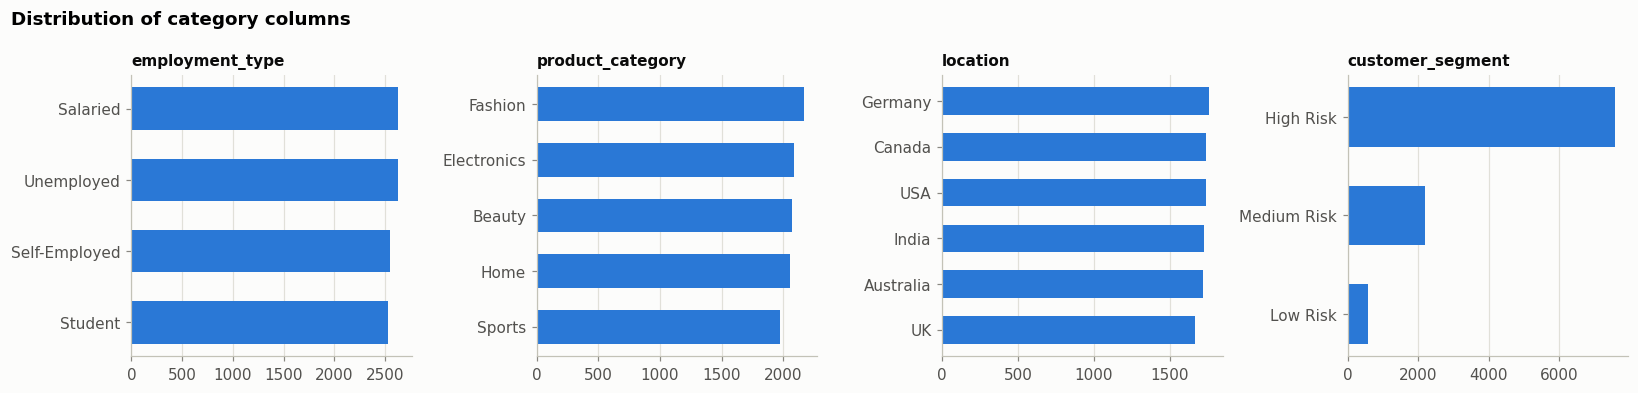

In [13]:
cat_cols = ["employment_type", "product_category", "location", "customer_segment"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, c in zip(axes, cat_cols):
    vc = df[c].value_counts()
    ax.barh(vc.index[::-1], vc.values[::-1], color=BLUE, height=0.6)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_title(c, fontsize=10)
fig.suptitle("Distribution of category columns", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**What we see:** employment, product category and country each split almost evenly. `customer_segment` is very lopsided: **73% "High Risk"**, only 6% "Low Risk".

## 6. Which columns are related to default? (bivariate analysis)

This is the **heart of the EDA**. Everything so far was preparation; now we ask the question that matters for a credit score: *which customer characteristics are linked to default?*

**The method in one sentence:** for each feature, split customers into groups and compare the **default rate** of each group with the **overall default rate** (the dashed orange line).

**How to judge a feature:**
| What the bars look like | What it means |
|---|---|
| Big differences between bars (some far above the line, some far below) | **Strong** feature: keep it |
| Steady rise or fall across ordered bands | Smooth relationship: the feature works across its whole range |
| Flat, then a sudden jump or drop | **Threshold** effect: suggests a natural policy cut-off |
| All bars close to the dashed line | **Weak / useless** feature: probably drop it |
| Big difference, but one bar has very few customers (small `n`) | Treat with caution: could be chance |

We start with the features a lender would expect to matter most (credit score, employment, income, affordability, repayment history) and finish with the ones we expect to be irrelevant.

### 6.1 Credit score

#### What we're doing
**Bivariate analysis** ("bi" = two): looking at a feature *together with the target*. We start with the most important credit feature, the **credit score**.

**Method (used for every numeric feature in this section):**
1. **Band** the numeric column into groups.
2. For each band, compute the **default rate**.
3. Plot the rates as bars and compare them against the overall rate.

**How to read the result:**
- If the bars **rise or fall steadily**, the feature has a smooth relationship with default.
- If the bars are **flat**, then a big drop or jump, the feature has a **threshold** (a "cliff"). This is very useful for credit policy, because it suggests a natural cut-off.
- If all bars are **near the dashed line**, the feature doesn't help predict default.

**Why bands instead of a scatter plot?** The target is only 0 or 1, so a scatter plot of credit score vs default would show two flat lines of dots, which is unreadable. Banding turns it into rates we can compare.

#### How the code works
- `score_bins` lists the **edges** of the bands: `[299, 300, 400, ...]`. `pd.cut` puts each score into the band between two edges. By default, bands include the right edge and exclude the left one, so (299, 300] contains exactly 300, (300, 400] contains 301–400, and so on.
- `labels` gives each band a readable name. The result is stored as a new column, `credit_band`.
- `plot_default_rate(...)` is our helper from Section 1: it groups by `credit_band` and draws the default rate per band.
- `default_table(...)` shows the same numbers as a table: customers per band, defaults per band, and the default rate.

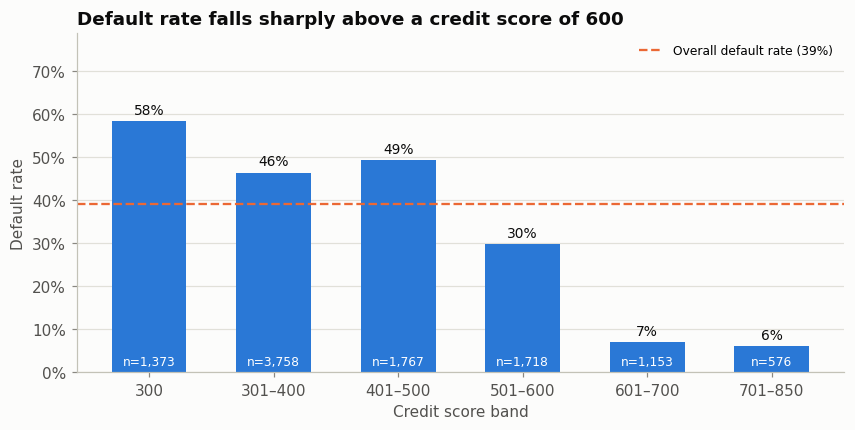

,customers,defaults,default_rate
credit_band,,,
300,1373,801,58.3%
301–400,3758,1742,46.4%
401–500,1767,871,49.3%
501–600,1718,511,29.7%
601–700,1153,80,6.9%
701–850,576,35,6.1%


In [14]:
score_bins   = [299, 300, 400, 500, 600, 700, 850]
score_labels = ["300", "301–400", "401–500", "501–600", "601–700", "701–850"]
df["credit_band"] = pd.cut(df["credit_score"], bins=score_bins, labels=score_labels)

fig, ax = plt.subplots(figsize=(9, 4))
plot_default_rate(df, "credit_band", "Default rate falls sharply above a credit score of 600",
                  xlabel="Credit score band", ax=ax)
plt.show()
default_table(df, "credit_band")

**What we see:** credit score is a **strong** driver, but it behaves like a **cliff, not a slope**:

- At **300**, 58% default (likely "no credit history" customers).
- From **301 to 500**, default stays around 46–49%.
- **501–600** drops to about 30%.
- **Above 600**, default falls to about **6–7%**.

In credit-policy terms, 600 looks like a natural cut-off.

### 6.2 Employment type

#### What we're doing
Default rate by **employment type**, a categorical feature. No banding is needed: the categories are already groups.

In lending, employment type is a classic **stability** indicator: a steady salary suggests a steady ability to repay. We'd expect students and unemployed customers to be riskier.

#### How the code works
- `order` sets the order of the bars (lowest to highest risk, which we found by looking at the data first). Without it, pandas sorts categories alphabetically, which makes patterns harder to see.
- The rest is our helper function again.

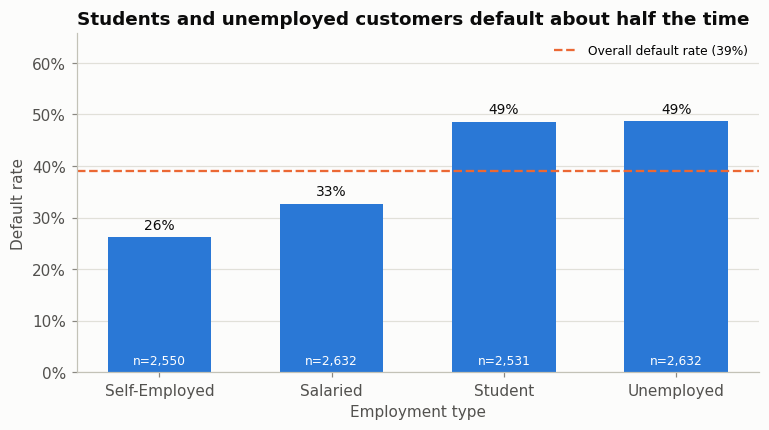

In [15]:
order = ["Self-Employed", "Salaried", "Student", "Unemployed"]
fig, ax = plt.subplots(figsize=(8, 4))
plot_default_rate(df, "employment_type", "Students and unemployed customers default about half the time",
                  order=order, xlabel="Employment type", ax=ax)
plt.show()

#### What we're doing
Checking whether employment type is **tangled up** with other features. If students also have much lower incomes and credit scores, then part of "students default more" may really be "low-income, low-score customers default more".

This is called **confounding**: when the effect you see from one feature is partly caused by another feature that moves with it. It's why we look at feature combinations in Section 9.

#### How the code works
- `df.groupby("employment_type")` splits customers by employment type.
- `[["monthly_income", "credit_score"]]` picks two columns (note the double brackets).
- `.median()` gives the median of each column per group. We use the median instead of the mean because income is skewed.
- `.reindex(order)` puts the rows in the same order as the chart above.

In [16]:
df.groupby("employment_type")[["monthly_income", "credit_score"]].median().reindex(order)

,monthly_income,credit_score
employment_type,,
Self-Employed,"60,824.92",576.00
Salaried,"50,836.46",526.00
Student,"15,427.23",349.00
Unemployed,"10,086.10",321.00


**What we see:** employment matters a lot: self-employed 26%, salaried 33%, students and unemployed about **49%**.

But look at the second table: students and unemployed customers also have **much lower incomes and credit scores**. So part of the employment effect is really an income / credit-score effect. Columns that move together like this are called **correlated** features (more in Section 8).

### 6.3 Monthly income

#### What we're doing
Default rate by **monthly income**.

Here we use **quintiles** instead of fixed bands: `pd.qcut` splits customers into 5 groups with **equal numbers of customers** (about 2,069 each). Income is heavily right-skewed, so fixed bands (like 0–20k, 20k–40k, ...) would put most customers in the first band and leave the top bands nearly empty. Quintiles guarantee every bar is based on enough customers.

The trade-off is that the bands have uneven widths. The second table shows the actual income range of each quintile.

#### How the code works
- `pd.qcut(column, q=5, labels=[...])` makes 5 equal-sized groups and names them.
- `.agg(["min", "max"])` shows the smallest and largest income in each group, so we know where the boundaries fall.
- `observed=True` tells pandas to show only the groups that actually exist. It's a technical setting for banded columns.

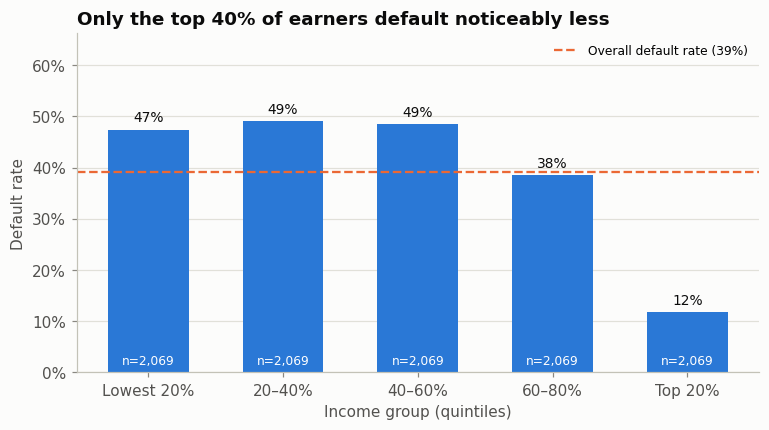

,min,max
income_band,,
Lowest 20%,"5,000.00","10,740.57"
20–40%,"10,749.41","17,376.52"
40–60%,"17,386.70","38,386.31"
60–80%,"38,388.23","61,222.32"
Top 20%,"61,223.36","145,767.12"


In [17]:
df["income_band"] = pd.qcut(df["monthly_income"], q=5,
                            labels=["Lowest 20%", "20–40%", "40–60%", "60–80%", "Top 20%"])
fig, ax = plt.subplots(figsize=(8, 4))
plot_default_rate(df, "income_band", "Only the top 40% of earners default noticeably less",
                  xlabel="Income group (quintiles)", ax=ax)
plt.show()
df.groupby("income_band", observed=True)["monthly_income"].agg(["min", "max"])

**What we see:** the bottom 60% of earners all default at around **48%**. The rate drops to 39% for the 60–80% group, and to just **12%** for the top 20%. Like credit score, income works more like a threshold than a straight line.

### 6.4 Debt-to-income ratio (affordability)

In this dataset, `debt_to_income_ratio` = purchase amount ÷ monthly income (we verify this in Section 7). It measures how big the purchase is compared to what the customer earns.

#### What we're doing
Default rate by **debt-to-income ratio (DTI)**, the affordability measure every lender uses.

**DTI** compares what a customer owes to what they earn. A DTI of 0.25 means the purchase is 25% of a month's income. Higher DTI = the repayment takes a bigger bite out of income = less room for error if something goes wrong = higher risk. Mortgage lenders, for example, typically cap total DTI at around 40–45%.

#### How the code works
Same pattern as the credit score: define band edges (`dti_bins`, as decimals: 0.05 = 5%), give them labels, `pd.cut` into a new column, plot with the helper.

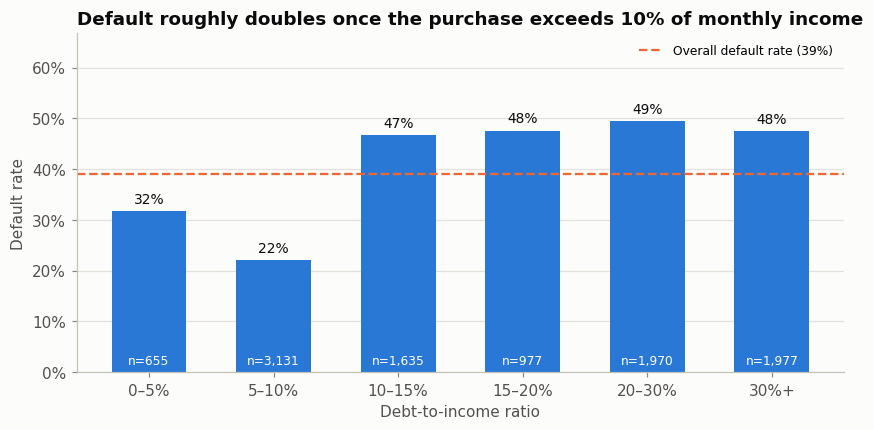

In [18]:
dti_bins   = [0, 0.05, 0.10, 0.15, 0.20, 0.30, 1.0]
dti_labels = ["0–5%", "5–10%", "10–15%", "15–20%", "20–30%", "30%+"]
df["dti_band"] = pd.cut(df["debt_to_income_ratio"], bins=dti_bins, labels=dti_labels)
fig, ax = plt.subplots(figsize=(9, 4))
plot_default_rate(df, "dti_band", "Default roughly doubles once the purchase exceeds 10% of monthly income",
                  xlabel="Debt-to-income ratio", ax=ax)
plt.show()

**What we see:** below 10% DTI, default is 22–32%. Above 10%, it jumps to **47–49%** and stays there. This is the familiar affordability rule from lending.

### 6.5 Past repayment behaviour: missed payments and delay days

#### What we're doing
Default rate by **past repayment behaviour**: number of missed payments and days of repayment delay.

In credit risk, **past behaviour is usually the strongest predictor of future behaviour**. A customer who has missed payments before is far more likely to miss them again. Behavioural scorecards at banks rely heavily on exactly these kinds of features.

#### How the code works
- `missed_payments` runs from 0 to 7, but only a handful of customers have 5, 6 or 7, too few for reliable rates. `.clip(upper=4)` caps every value above 4 at 4, so 4, 5, 6 and 7 become one group. We then turn it into text and rename "4" to "4+". Merging rare values like this is standard practice.
- `delay_band` uses `pd.cut` with edges `[-1, 5, 10, 15, 20, 40]`. The first edge is −1 so that 0 days is included in the first band.
- `plt.subplots(1, 2, ...)` makes two charts side by side; we pass `ax=axes[0]` and `ax=axes[1]` to tell the helper where to draw each one.

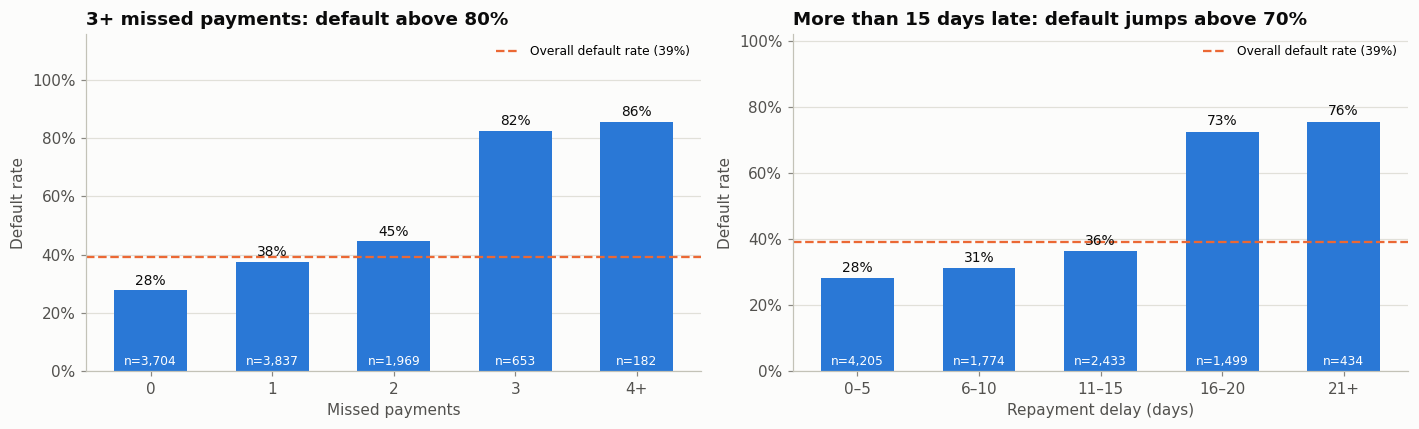

In [19]:
df["missed_group"] = df["missed_payments"].clip(upper=4).astype(int).astype(str).replace({"4": "4+"})
df["delay_band"] = pd.cut(df["repayment_delay_days"], bins=[-1, 5, 10, 15, 20, 40],
                          labels=["0–5", "6–10", "11–15", "16–20", "21+"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_default_rate(df, "missed_group", "3+ missed payments: default above 80%",
                  order=["0", "1", "2", "3", "4+"], xlabel="Missed payments", ax=axes[0])
plot_default_rate(df, "delay_band", "More than 15 days late: default jumps above 70%",
                  xlabel="Repayment delay (days)", ax=axes[1])
plt.tight_layout()
plt.show()

**What we see:** both are strong signals, and both have a clear threshold:

- **Missed payments:** 0 → 28%, 1 → 38%, 2 → 45%, **3 or more → over 80%**.
- **Delay days:** up to 15 days late → 28–36%; **more than 15 days → 73–76%**.

#### Important: is this "leakage"?

**Leakage** means using information the lender would *not* have at the moment of approving the loan. For example, if `missed_payments` counted missed payments **on this same loan**, it would be partly the answer itself, and the model would look far better than it really is.

We can test this. If these columns described *this* loan, a customer with **0 missed payments and 0 days late could never have defaulted**.

#### What we're doing
A **leakage test**. The question: do `missed_payments` and `repayment_delay_days` describe the customer's **past** loans (fine to use), or **this** loan (leakage)?

The logic is like checking an accounting identity. If these columns described *this* loan, then a customer with **zero missed payments and zero days late** must have paid this loan on time, so they **cannot** have defaulted on it. Their default rate would have to be exactly 0%. If it's well above 0%, the columns must be describing something else, most likely past history.

#### How the code works
- `(df["missed_payments"] == 0) & (df["repayment_delay_days"] == 0)` gives True only for rows where **both** conditions hold. `&` means "and"; each condition must be wrapped in brackets.
- `df.loc[clean_record, "default_flag"]` selects the default flag for only those rows. `.loc[rows, column]` is pandas' way to pick specific rows and columns.
- `.mean()` gives their default rate.

In [20]:
clean_record = (df["missed_payments"] == 0) & (df["repayment_delay_days"] == 0)
print(f"Customers with 0 missed payments AND 0 delay days: {clean_record.sum():,}")
print(f"Their default rate: {df.loc[clean_record, 'default_flag'].mean():.1%}")

Customers with 0 missed payments AND 0 delay days: 1,153
Their default rate: 28.2%


**What we see:** 28% of customers with a perfect record still defaulted. So these columns **cannot** be about the current loan.

**Our assumption:** `missed_payments` and `repayment_delay_days` describe the customer's **past** repayment history, which a lender *would* know at approval time. We therefore treat them as **valid features**. This should be stated clearly in the report, since the dataset has no documentation.

### 6.6 Age

#### What we're doing
Default rate by **age**. Age often shows a mild effect in credit data: younger customers have shorter credit histories and less financial cushion.

Note: in many countries, using age (or gender, race, etc.) in credit decisions is **regulated** to prevent discrimination. It's fine to *explore* it in EDA, but whether to use it in a final model is a policy question worth a sentence in the report.

#### How the code works
Same pattern: band edges, labels, `pd.cut`, helper plot.

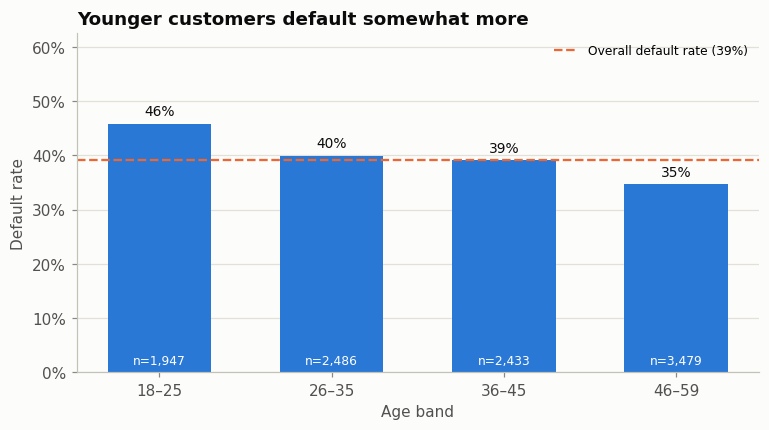

In [21]:
df["age_band"] = pd.cut(df["age"], bins=[17, 25, 35, 45, 59], labels=["18–25", "26–35", "36–45", "46–59"])
fig, ax = plt.subplots(figsize=(8, 4))
plot_default_rate(df, "age_band", "Younger customers default somewhat more", xlabel="Age band", ax=ax)
plt.show()

**What we see:** a mild effect: 46% for 18–25 down to 35% for 46–59. Part of this is again income and credit score, which are lower for younger customers.

### 6.7 Columns that do **not** matter

Equally important: knowing which columns we can drop.

#### What we're doing
Checking the **remaining features** all at once, to confirm which ones do *not* matter.

This is just as valuable as finding the strong features. Every useless feature we drop makes the final model **simpler, easier to explain, and less likely to pick up noise**. In credit risk, explainability matters a lot: regulators and customers can ask why an application was declined.

We also check **purchase amount** in a special way. Because 59% of purchases are capped at exactly 5,000, we compare "capped" vs "below 5,000" customers.

#### How the code works
- We create a few new grouping columns:
  - `app_usage_band`: bands of app usage frequency.
  - `quarter`: the transaction quarter as text.
  - `purchase_capped`: built with `np.where(condition, value_if_true, value_if_false)`, which labels each row "= 5,000 (capped)" or "< 5,000".
- `plt.subplots(2, 3, ...)` makes a 2 × 3 grid. `axes[0, 0]` is the top-left chart, `axes[1, 2]` the bottom-right.
- The final loop tilts the x-axis labels by 20° so long names don't overlap.

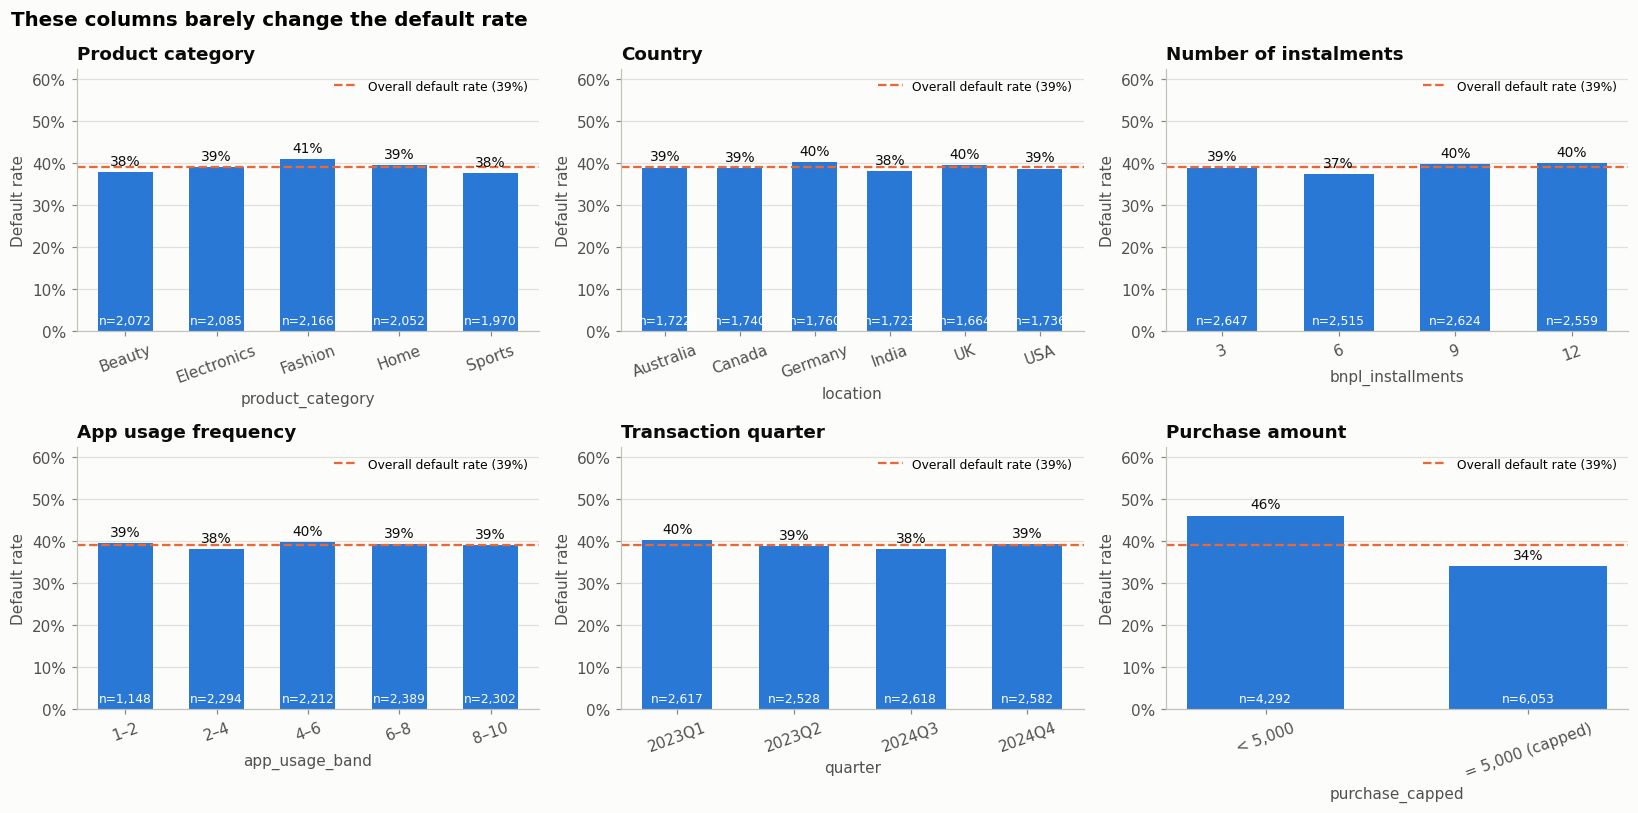

In [22]:
df["app_usage_band"] = pd.cut(df["app_usage_frequency"], bins=[0, 2, 4, 6, 8, 10],
                              labels=["1–2", "2–4", "4–6", "6–8", "8–10"])
df["quarter"] = df["transaction_date"].dt.to_period("Q").astype(str)

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
plot_default_rate(df, "product_category", "Product category", ax=axes[0, 0])
plot_default_rate(df, "location", "Country", ax=axes[0, 1])
plot_default_rate(df, "bnpl_installments", "Number of instalments", ax=axes[0, 2])
plot_default_rate(df, "app_usage_band", "App usage frequency", ax=axes[1, 0])
plot_default_rate(df, "quarter", "Transaction quarter", ax=axes[1, 1])
df["purchase_capped"] = np.where(df["purchase_amount"] == 5000, "= 5,000 (capped)", "< 5,000")
plot_default_rate(df, "purchase_capped", "Purchase amount", ax=axes[1, 2])
for ax in axes.ravel():
    ax.tick_params(axis="x", labelrotation=20)
fig.suptitle("These columns barely change the default rate", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

**What we see:**

- **Product category, country, number of instalments, app usage and date** all sit at 38–41%, right on the overall line. **They don't help predict default.** The flat date pattern also means the one-year gap in the data is not a problem.
- **Purchase amount** goes the "wrong" way: capped (5,000) purchases default *less* (34% vs 46%). That's because only higher earners get the full 5,000. The cap makes this column unreliable on its own; the **debt-to-income ratio** captures the useful part (amount relative to income).

## 7. Checking the pre-calculated columns

Three columns look like they were *calculated from other columns*. If so, they add no new information, and using them alongside their ingredients can confuse a model.

### 7.1 Is `debt_to_income_ratio` = purchase ÷ income?

#### What we're doing
Section 7 checks whether some columns are **derived**, meaning calculated from other columns. A derived column adds **no new information**. And if a column is derived from a leaky column, it is leaky too.

First, the hypothesis that `debt_to_income_ratio` = `purchase_amount` ÷ `monthly_income`.

#### How the code works
- `df["purchase_amount"] / df["monthly_income"]` divides the two columns **row by row**. pandas does this for all 10,345 rows at once, without a loop.
- `np.isclose(a, b)` checks whether two numbers are equal *allowing for tiny rounding differences*. Computers store decimals with tiny errors, so `0.1 + 0.2 == 0.3` is actually False in Python. `isclose` handles this.
- `.mean()` of True/False values gives the share of matching rows (True = 1, False = 0).

In [23]:
calc_dti = df["purchase_amount"] / df["monthly_income"]
match = np.isclose(calc_dti, df["debt_to_income_ratio"])
print(f"Rows where DTI equals purchase_amount / monthly_income: {match.mean():.1%}")

Rows where DTI equals purchase_amount / monthly_income: 100.0%


**What we see:** it matches on 100% of rows. So DTI is a ratio of two other columns. That's fine; it's actually the most useful form of that information. But in a model we should use **either** the ratio **or** the two raw columns, not all three.

### 7.2 How is `risk_score` calculated?

We fit a simple linear regression of `risk_score` on the other numeric columns to see if it is an exact formula.

#### What we're doing
Reverse-engineering `risk_score` to see if it's a fixed formula.

We use **linear regression**: a method that finds the best weights so that
`risk_score ≈ intercept + w1 × credit_score + w2 × missed_payments + ...`.
If the weights come out as neat round numbers and the formula matches every row exactly, the column is a hand-built formula, not independent information.

(You likely know regression from finance, e.g. estimating a stock's beta against the market. Same idea.)

#### How the code works
- `X` holds the candidate input columns. `.assign(intercept=1.0)` adds a column of 1s, which lets the regression find a constant term (the intercept).
- `np.linalg.lstsq(...)` solves the regression by **least squares** (finding the weights that minimise the squared prediction errors). `coef` holds the weights. The `*_` part discards extra outputs we don't need.
- We print the weights, then plug the round-number formula back in and check with `np.isclose` that it matches every row.

In [24]:
X = df[["credit_score", "missed_payments", "repayment_delay_days", "monthly_income",
        "debt_to_income_ratio", "age"]].assign(intercept=1.0)
coef, *_ = np.linalg.lstsq(X.values, df["risk_score"].values, rcond=None)
print(pd.Series(coef, index=X.columns).round(4).to_string())

formula = 340 - 0.4 * df["credit_score"] + 20 * df["missed_payments"] + 2 * df["repayment_delay_days"]
print(f"\nRows matching the formula exactly: {np.isclose(formula, df['risk_score']).mean():.1%}")

credit_score            -0.40
missed_payments         20.00
repayment_delay_days     2.00
monthly_income           0.00
debt_to_income_ratio     0.00
age                     -0.00
intercept              340.00

Rows matching the formula exactly: 100.0%


**What we see:** `risk_score` is **exactly**:

$$\text{risk\_score} = 340 - 0.4 \times \text{credit\_score} + 20 \times \text{missed\_payments} + 2 \times \text{repayment\_delay\_days}$$

It is a simple **rule-based score** built from three columns we already have. **Drop it as a model feature.** It is still useful as a **benchmark**: "Does my model beat the existing rule-based score?"

### 7.3 What is `customer_segment` based on?

#### What we're doing
Checking what `customer_segment` (High / Medium / Low Risk) is based on.

A **crosstab** (cross-tabulation, like an Excel pivot table with counts) shows how many customers fall in each combination of two categories. If each segment lines up neatly with certain credit-score bands, the segment is essentially a credit-score band in disguise.

#### How the code works
`pd.crosstab(rows, columns)` counts customers for each pair of (segment, credit band). `.reindex([...])` orders the rows Low → Medium → High.

In [25]:
pd.crosstab(df["customer_segment"], df["credit_band"]).reindex(["Low Risk", "Medium Risk", "High Risk"])

credit_band,300,301–400,401–500,501–600,601–700,701–850
customer_segment,,,,,,
Low Risk,0,0,0,0,0,576
Medium Risk,246,0,0,801,1153,0
High Risk,1127,3758,1767,917,0,0


#### What we're doing
Default rate by segment. This shows how well the existing segmentation separates good and bad customers. It's a useful **benchmark**: our final model should separate them *at least* as well.

#### How the code works
Our helper function, with a custom bar order.

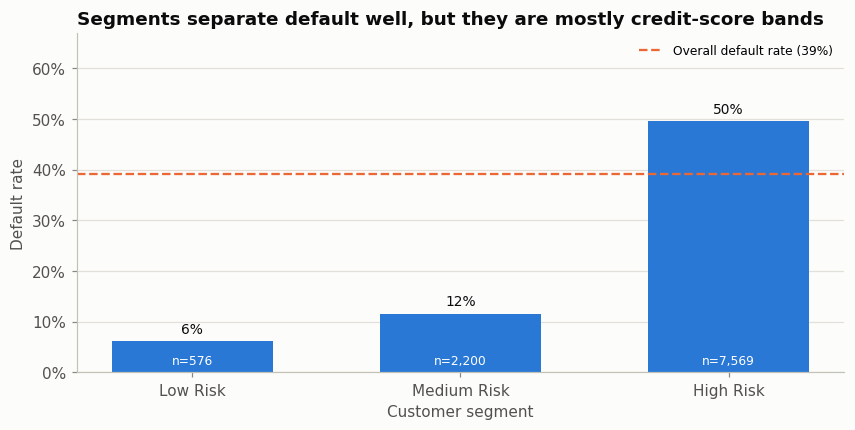

In [26]:
fig, ax = plt.subplots(figsize=(9, 4))
plot_default_rate(df, "customer_segment", "Segments separate default well, but they are mostly credit-score bands",
                  order=["Low Risk", "Medium Risk", "High Risk"], xlabel="Customer segment", ax=ax)
plt.show()

**What we see:** "Low Risk" customers all have scores above 700, "High Risk" all have 550 or below, and "Medium Risk" is mostly 501–700. The segment is largely a **credit-score band** with some extra rules (for example, 246 customers with a score of 300 are labelled "Medium"). It separates default well (6% / 12% / 50%), but it adds little beyond `credit_score`. **Drop it as a feature**, or keep it as a second benchmark.

## 8. Correlations between numeric columns

In Section 6 we compared default rates group by group. Correlation gives a **single summary number** for every pair of numeric columns, so we can see all relationships at once.

**Correlation recap** (see Section 0.3): a value from −1 to +1. **+1** = move up together, **−1** = move in opposite directions, **0** = no straight-line relationship.

- Blue = negative, red = positive, white = none.
- The last row/column shows each feature's correlation with `default_flag`.

**An important limitation:** correlation only detects **straight-line** relationships. A feature with a **cliff-shaped** effect (flat, then a sudden drop, like credit score in Section 6.1) can be very predictive yet show only a modest correlation. That's why we also use banded default rates (Section 6) and Information Value (Section 10).

#### What we're doing
**Correlation analysis**: computing the correlation between every pair of numeric columns at once, and showing it as a **heatmap** (a grid where colour shows the value).

This answers two questions:
1. **Which features are most related to default?** Look at the bottom row (`default_flag`).
2. **Which features are related to each other?** Look for strong colours *away from the diagonal*. Strongly correlated feature pairs carry overlapping information (**multicollinearity**, see Section 0.3).

**How to read the heatmap:**
- Each cell is the correlation between the row's column and the column's column.
- **Red = positive** (move together), **blue = negative** (move in opposite directions), **near-white = no relationship**. Darker = stronger.
- The diagonal is always 1.00 (every column correlates perfectly with itself).
- The grid is symmetric: the cell (A, B) equals the cell (B, A).

Correlation can be computed with a 0/1 target. It then measures how much the default rate rises or falls as the feature increases.

#### How the code works
- `df[corr_cols].corr()` computes the full correlation table (Pearson correlation, the standard kind).
- `LinearSegmentedColormap.from_list(...)` builds a blue → light grey → red colour scale. `vmin=-1, vmax=1` pins the colour scale so that 0 is always in the middle.
- `ax.imshow(corr, ...)` draws the grid as an image.
- The nested loops (`for i ... for j ...`) write each number into its cell. Text is white on dark cells and black on light cells, so it stays readable.

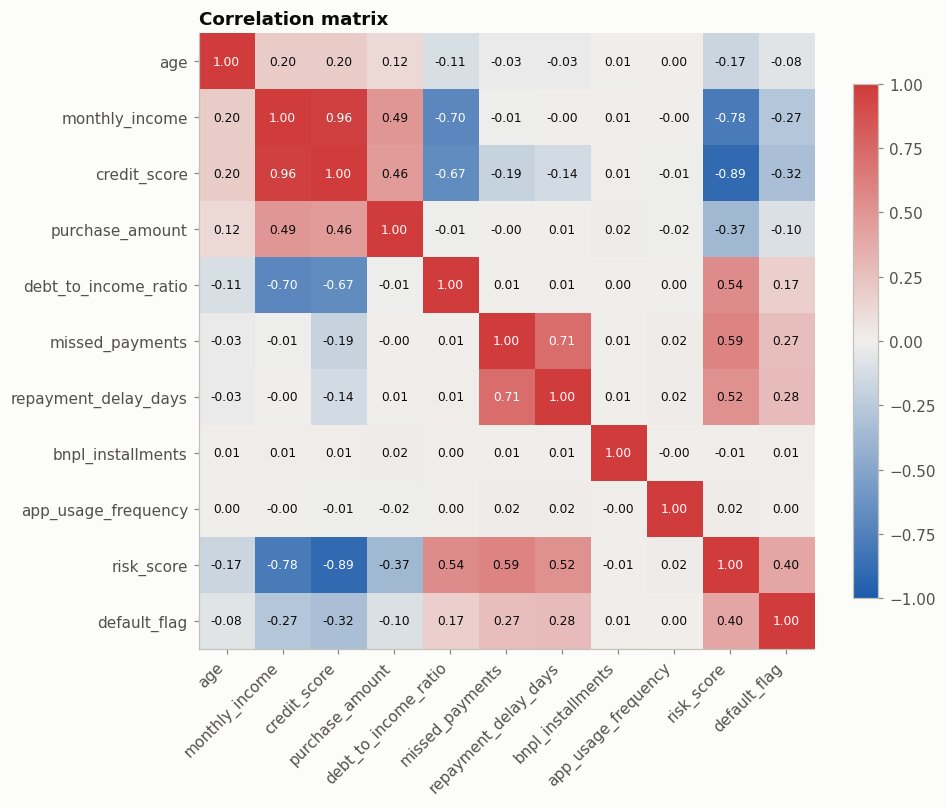

In [27]:
from matplotlib.colors import LinearSegmentedColormap

corr_cols = ["age", "monthly_income", "credit_score", "purchase_amount", "debt_to_income_ratio",
             "missed_payments", "repayment_delay_days", "bnpl_installments", "app_usage_frequency",
             "risk_score", "default_flag"]
corr = df[corr_cols].corr()

diverging = LinearSegmentedColormap.from_list("blue_red", ["#1c5cab", "#f0efec", "#d03b3b"])
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
ax.grid(False)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else INK)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

#### What we're doing
Pulling out just the **correlation of each feature with default**, sorted from most negative to most positive. This is easier to read than the full grid.

- **Negative:** higher values → *lower* default risk (e.g. credit score).
- **Positive:** higher values → *higher* default risk (e.g. missed payments).

#### How the code works
- `corr["default_flag"]` takes the `default_flag` column of the correlation table.
- `.drop("default_flag")` removes its correlation with itself (always 1).
- `.sort_values()` sorts; `.to_frame(...)` turns the result into a neat one-column table with a header.

In [28]:
corr["default_flag"].drop("default_flag").sort_values().to_frame("correlation with default")

,correlation with default
credit_score,-0.32
monthly_income,-0.27
purchase_amount,-0.10
age,-0.08
app_usage_frequency,0.00
bnpl_installments,0.01
debt_to_income_ratio,0.17
missed_payments,0.27
repayment_delay_days,0.28
risk_score,0.40


**What we see:**

1. **Strongest relationships with default:** `credit_score` (−0.32), `repayment_delay_days` (+0.28), `monthly_income` (−0.27), `missed_payments` (+0.27), `debt_to_income_ratio` (+0.17). (`risk_score` is +0.40, but it is built from three of these.)
2. **`monthly_income` and `credit_score` are almost the same thing (0.96).** This is called **multicollinearity**. In a logistic regression it makes the coefficients unstable and hard to interpret. Consider keeping only one of them, or watching their coefficients closely.
3. `missed_payments` and `repayment_delay_days` are also correlated (0.71); together they describe "past repayment behaviour".
4. Correlation only measures *straight-line* relationships. Credit score and income have **cliff-shaped** effects (Section 6), so their true predictive power is higher than these numbers suggest. Banding them (as credit scorecards do) captures this better.

## 9. Combining two drivers: employment × credit score

Does a high credit score protect a student or unemployed customer? A heatmap of default rate across two columns shows this.

#### What we're doing
**Interaction analysis**: looking at **two features at the same time**. In Section 6.2 we saw that students and unemployed customers default much more, but also that they have much lower credit scores. So which one is really driving default?

By splitting customers by **both** employment type **and** credit band, we can compare like with like. For example: *among customers with scores of 601–700*, do students still default more than salaried customers? If the employment difference disappears within each score band, then employment was mostly standing in for credit score.

The heatmap shows the **default rate** in each cell: darker blue = higher default rate. Cells with fewer than 30 customers are greyed out, because a rate based on a handful of people isn't reliable. (30 is a common rule-of-thumb minimum sample size.)

#### How the code works
- `df.pivot_table(index=..., columns=..., values="default_flag", aggfunc="mean")` builds a pivot table, just like Excel: employment types as rows, credit bands as columns, and the average default flag (= default rate) in each cell.
- The second `pivot_table` with `aggfunc="size"` counts customers per cell.
- `pivot.where(counts2 >= 30)` keeps a rate only where the cell has 30+ customers and blanks the rest. Blank cells are drawn grey.
- `imshow` draws the grid; the loop writes the rate and count into each cell.

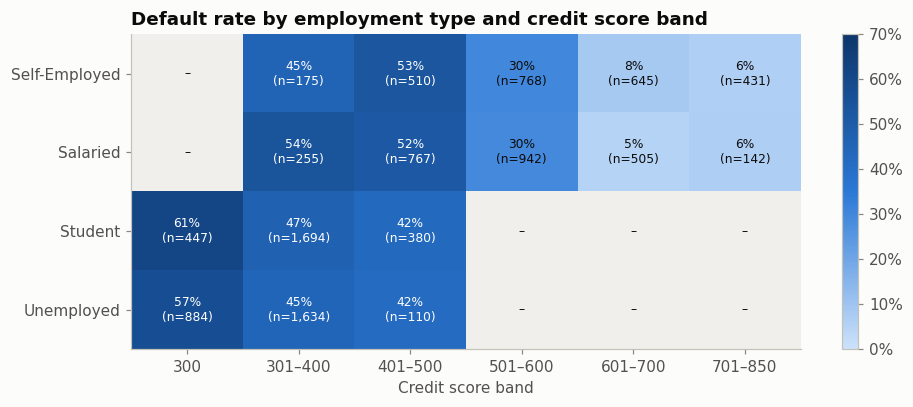

In [29]:
pivot = df.pivot_table(index="employment_type", columns="credit_band", values="default_flag",
                       aggfunc="mean", observed=False).reindex(order)
counts2 = df.pivot_table(index="employment_type", columns="credit_band", values="default_flag",
                         aggfunc="size", observed=False).reindex(order)

pivot = pivot.where(counts2 >= 30)   # hide cells with fewer than 30 customers
sequential = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#2a78d6", "#0d366b"])
sequential.set_bad("#f0efec")
fig, ax = plt.subplots(figsize=(9, 3.8))
im = ax.imshow(np.ma.masked_invalid(pivot.values.astype(float)), cmap=sequential, vmin=0, vmax=0.7, aspect="auto")
ax.set_xticks(range(pivot.shape[1]), pivot.columns)
ax.set_yticks(range(pivot.shape[0]), pivot.index)
ax.grid(False)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v, n = pivot.iloc[i, j], counts2.iloc[i, j]
        label = "–" if n < 30 or pd.isna(v) else f"{v:.0%}\n(n={n:,})"
        ax.text(j, i, label, ha="center", va="center", fontsize=8,
                color="white" if (not pd.isna(v) and v > 0.35) else INK)
ax.set_xlabel("Credit score band")
ax.set_title("Default rate by employment type and credit score band")
fig.colorbar(im, ax=ax, format=mtick.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

**What we see:** grey cells marked "–" have fewer than 30 customers, too few to trust.

- **Credit score dominates.** For salaried and self-employed customers, default falls from ~50% to ~6% once the score passes 600.
- **Students and unemployed customers almost never have scores above 500**, which is why they look so risky in Section 6.2.
- **Within the same score band, employment makes little consistent difference.** In the 301–400 band, for example, salaried customers (54%) actually default *more* than students (47%).
- So most of the employment effect is really a **credit-score effect**. Employment is still worth testing in the model, but it may add little once credit score is included. The IV in the next section agrees: employment is only "medium".

## 10. Ranking the features: Information Value (IV)

**Information Value** is the standard way credit-risk teams rank features for a scorecard. For each band of a feature it compares the share of *good* customers with the share of *bad* customers. The bigger the difference, the more useful the feature.

For each band:

$$\text{WoE} = \ln\left(\frac{\%\ \text{of goods in band}}{\%\ \text{of bads in band}}\right) \qquad \text{IV} = \sum (\%\text{goods} - \%\text{bads}) \times \text{WoE}$$

**WoE** (Weight of Evidence) is positive for "safer than average" bands and negative for "riskier than average" bands.

| IV | Predictive power (rule of thumb) |
|---|---|
| < 0.02 | Useless |
| 0.02 – 0.1 | Weak |
| 0.1 – 0.3 | Medium |
| 0.3 – 0.5 | Strong |
| > 0.5 | Very strong. Double-check it is not leakage |

Numeric columns are first split into 10 equal-sized bands (deciles). Without banding, every unique value would count as its own group and the IV would be hugely inflated.

#### What we're doing
**Ranking every feature by predictive power** using **Information Value (IV)**, the standard method in credit scorecard development (used by banks for decades, and expected in credit risk assignments).

**The intuition.** A feature is useful if its groups contain *different mixes* of good and bad customers. Take credit score bands: if the "300" band holds 20% of all bad customers but only 10% of all good customers, being in that band is evidence of risk. IV adds up that evidence across all bands.

**Step by step, for one feature:**
1. Split customers into bands (we use 10 equal-sized bands, called deciles, for numeric features; categories as-is for categorical ones).
2. For each band, compute:
   - **%goods** = goods in this band ÷ all goods in the data
   - **%bads** = bads in this band ÷ all bads in the data
3. **Weight of Evidence (WoE)** for the band = ln(%goods ÷ %bads).
   - WoE > 0: more goods than bads, so a *safer* band.
   - WoE < 0: more bads than goods, so a *riskier* band.
   - WoE = 0: same mix as the overall population, so the band tells us nothing.
4. **IV** = sum over all bands of (%goods − %bads) × WoE.

Each term in the IV sum is always positive or zero (both parts have the same sign), so IV grows with every band that differs from average.

**Why ln (the natural logarithm)?** It turns the ratio into a symmetric scale: a band with twice as many goods as bads gets +0.69, and one with twice as many bads as goods gets −0.69. In the modelling stage, WoE values feed directly into logistic regression, which works on the same "log-odds" scale.

**A small worked example.** Suppose there are 600 goods and 400 bads in total, and one band contains 60 goods and 80 bads:
- %goods = 60 / 600 = 10%, %bads = 80 / 400 = 20%
- WoE = ln(0.10 / 0.20) = ln(0.5) = −0.69 (a risky band)
- This band's IV contribution = (0.10 − 0.20) × (−0.69) = 0.069

#### How the code works
- `information_value(data, col, bins)`:
  - If `bins` is given, `pd.qcut` splits the numeric column into that many equal-sized bands. `duplicates="drop"` handles columns like `purchase_amount`, where so many values are identical (5,000) that some band edges coincide.
  - `pd.crosstab(x, data["default_flag"])` counts goods (column `0`) and bads (column `1`) per band.
  - `good` and `bad` are the %goods and %bads per band.
  - `np.log(...)` is the natural log. `+ 1e-6` adds a tiny number (0.000001) so we never divide by zero or take the log of zero if a band happens to have no bads.
- `strength(iv)` turns the IV number into a word using the rule-of-thumb table above.
- `features` maps each column to its number of bands (`None` = use the categories or values as they are). A **dictionary comprehension**, `{c: information_value(df, c, b) for c, b in features.items()}`, computes IV for every feature in one line.

In [30]:
def information_value(data, col, bins=None):
    x = data[col]
    if bins is not None:
        x = pd.qcut(x, q=bins, duplicates="drop")
    t = pd.crosstab(x, data["default_flag"])
    good = t[0] / t[0].sum()
    bad = t[1] / t[1].sum()
    woe = np.log((good + 1e-6) / (bad + 1e-6))
    return ((good - bad) * woe).sum()


def strength(iv):
    if iv < 0.02: return "Useless"
    if iv < 0.1:  return "Weak"
    if iv < 0.3:  return "Medium"
    if iv < 0.5:  return "Strong"
    return "Very strong"


features = {
    "credit_score": 10, "monthly_income": 10, "debt_to_income_ratio": 10, "repayment_delay_days": 10,
    "missed_payments": None, "employment_type": None, "age": 10, "purchase_amount": 10,
    "bnpl_installments": None, "app_usage_frequency": 10, "product_category": None, "location": None,
    "risk_score": 10, "customer_segment": None,
}
iv = pd.DataFrame({"IV": {c: information_value(df, c, b) for c, b in features.items()}})
iv["strength"] = iv["IV"].apply(strength)
iv["note"] = ""
iv.loc[["risk_score", "customer_segment"], "note"] = "derived: benchmark only"
iv = iv.sort_values("IV", ascending=False)
iv

,IV,strength,note
risk_score,1.06,Very strong,derived: benchmark only
credit_score,0.73,Very strong,
customer_segment,0.71,Very strong,derived: benchmark only
repayment_delay_days,0.50,Strong,
monthly_income,0.48,Strong,
missed_payments,0.42,Strong,
debt_to_income_ratio,0.33,Strong,
employment_type,0.17,Medium,
purchase_amount,0.06,Weak,
age,0.03,Weak,


#### What we're doing
Showing the IV ranking as a chart, with dotted lines at the rule-of-thumb thresholds (weak 0.02, medium 0.1, strong 0.3). We leave out `risk_score` and `customer_segment` because they're derived from other features and won't go into the model.

#### How the code works
- `iv.drop([...])` removes the two derived rows; `.sort_values("IV")` sorts ascending, so the strongest feature ends up at the top of a horizontal bar chart.
- `ax.axvline(x, ...)` draws a vertical dotted line at each threshold, with a small label.

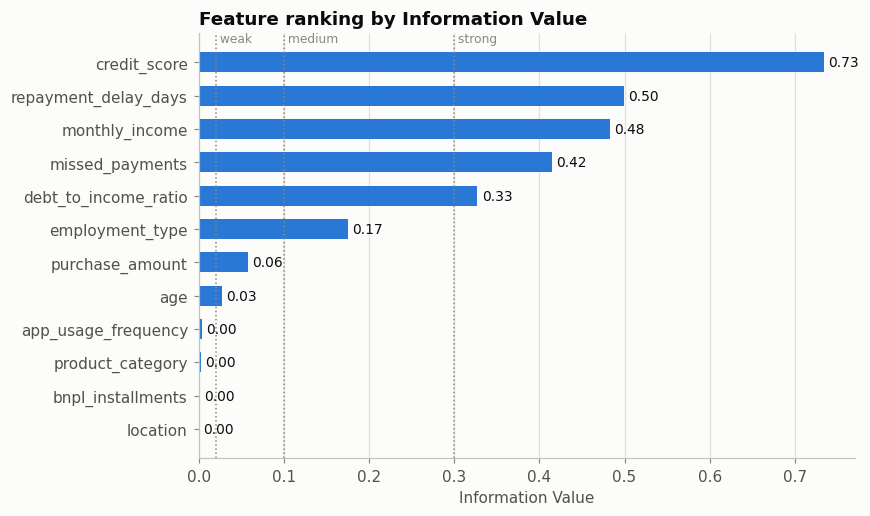

In [31]:
plot_iv = iv.drop(["risk_score", "customer_segment"]).sort_values("IV")
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(plot_iv.index, plot_iv["IV"], color=BLUE, height=0.6)
for y, v in enumerate(plot_iv["IV"]):
    ax.text(v + 0.005, y, f"{v:.2f}", va="center", fontsize=9, color=INK)
for x, label in [(0.02, "weak"), (0.1, "medium"), (0.3, "strong")]:
    ax.axvline(x, color=MUTED, linestyle=":", linewidth=1)
    ax.text(x, len(plot_iv) - 0.4, f" {label}", color=MUTED, fontsize=8)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Information Value")
ax.set_title("Feature ranking by Information Value")
plt.tight_layout()
plt.show()

**What we see:** the IV ranking confirms the charts in Section 6.

- **Very strong:** credit score (0.73). Above 0.5 we should ask "is this leakage?". It is not: a bureau credit score is known before the loan is approved. The value is high because this synthetic data has a very sharp score cut-off.
- **Strong:** repayment delay, monthly income, missed payments, debt-to-income ratio (0.33–0.50).
- **Medium:** employment type (0.17). Lower than its chart suggests, because much of its effect is already captured by income and credit score.
- **Weak:** purchase amount, age.
- **Useless:** product category, location, instalments, app usage.
- `risk_score` and `customer_segment` score high only because they are built from the strong features.

## 11. Summary of findings

### Data quality
- 10,345 customers, 17 columns, **no missing values, no duplicates**. One row per customer, no transaction history.
- **Capped values:** 59% of purchases = 5,000; 13% of credit scores = 300; 3% of incomes = 5,000.
- Dates cover Jan–Jun 2023 and Jul–Dec 2024 only. The default rate is flat over time, so this is not a problem.

### Target
- **39% default rate**. Classes are reasonably balanced.

### What drives default
| Feature | Effect | Shape |
|---|---|---|
| Credit score | 300 → 58%, above 600 → ~6% | Cliff at ~600 |
| Monthly income | Bottom 60% → ~48%, top 20% → 12% | Threshold |
| Employment | Student / Unemployed ~49%, Self-employed 26% | Mostly explained by credit score |
| Missed payments | 3+ → over 80% | Threshold at 3 |
| Repayment delay | More than 15 days → 73–76% | Threshold at 15 |
| Debt-to-income | Above 10% → ~48% | Threshold at 10% |
| Age | 18–25 → 46%, 46+ → 35% | Mild |

**No effect:** product category, location, instalments, app usage, transaction date.

### Assumptions and cautions
1. **`missed_payments` and `repayment_delay_days` are treated as past history** (not leakage), because 28% of customers with a clean record still defaulted.
2. **`risk_score` is an exact formula** of credit score, missed payments and delay. **`customer_segment`** is mostly credit-score bands. Use both as benchmarks only, not as features.
3. **`debt_to_income_ratio` = purchase ÷ income.** Use the ratio *or* the raw columns, not all three.
4. **Income and credit score are 0.96 correlated.** Watch out for multicollinearity in logistic regression.
5. The data appears **synthetic** (very high default rate, perfectly even categories), so findings may not carry over to real portfolios.

### Recommended feature set for the model
`credit_score`, `debt_to_income_ratio`, `missed_payments`, `repayment_delay_days`, `employment_type`, `age`, plus optionally `monthly_income` (watch the correlation with credit score). Employment and age are weaker and should be kept only if they improve the model on the test set.

### Next steps
1. Split data into **train / test** (e.g. 70 / 30, stratified on `default_flag`).
2. Build a **logistic regression** on WoE-transformed bands (the classic credit scorecard approach).
3. Evaluate with **AUC, Gini, KS statistic**, precision and recall. Compare against `risk_score` as a benchmark.
4. Convert the model into a **points-based scorecard** (e.g. 600 points = 50:50 odds, +20 points doubles the odds).